# MODIS SCAF

This notebook gives an example to compute glacier SCAF and SLA from MODIS given the glacier specific regression parameter `a` and `b`

In [1]:
import ee
import geemap

# Authenticate once on this machine if needed:
# ee.Authenticate()
ee.Initialize(project="YOUR_EARTH_ENGINE_PROJECT")


import matplotlib.pyplot as plt
from datetime import date, timedelta
import numpy as np

from glacier_scaf import MODIS_meanNIR, snowline_altitude

## 1) Select the inputs

In [2]:
start_date = "2018-06-01"
end_date = "2018-09-30"

### Select the glacier outline

In [3]:
glacier = ee.FeatureCollection("users/josiaszeller/RGVI_v6").filter(ee.Filter.eq('RGIId', 'RGI60-13.14451')).first() \
    .set('Name', 'Zulmart')
glacier_outline = glacier.geometry()

Map = geemap.Map()
Map.centerObject(glacier_outline, 12)
Map.addLayer(glacier_outline, {'color': 'red'}, 'glacier outline', True, 0.6);
Map

Map(center=[38.8631658918276, 72.99896883020456], controls=(WidgetControl(options=['position', 'transparent_bg…

### Set the regression parameters

In [4]:
a, b = 3.62, 5.423

## 2) Extract the MODIS mean NIR time series

In [5]:
modis_nir = MODIS_meanNIR(glacier_outline, start_date, end_date)

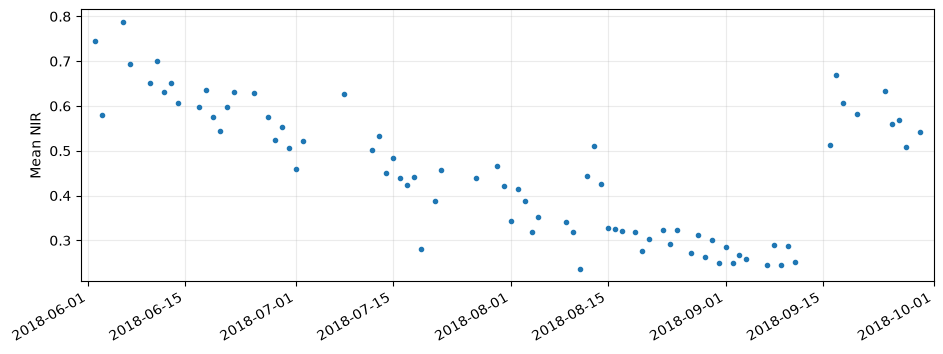

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(modis_nir.index, modis_nir.values, marker=".", linestyle="")
ax.set(ylabel="Mean NIR")
ax.grid(alpha=0.25)
ax.set_xlim(
    date.fromisoformat(start_date) - timedelta(days=1),
    date.fromisoformat(end_date) + timedelta(days=1),
)
fig.autofmt_xdate()
plt.show()

## 3) Compute the MODIS SCAF and SLA

In [17]:
modis_scaf = 100.0 * (1.0 - a * np.exp(-b * modis_nir))
modis_scaf = modis_scaf.clip(lower=0)

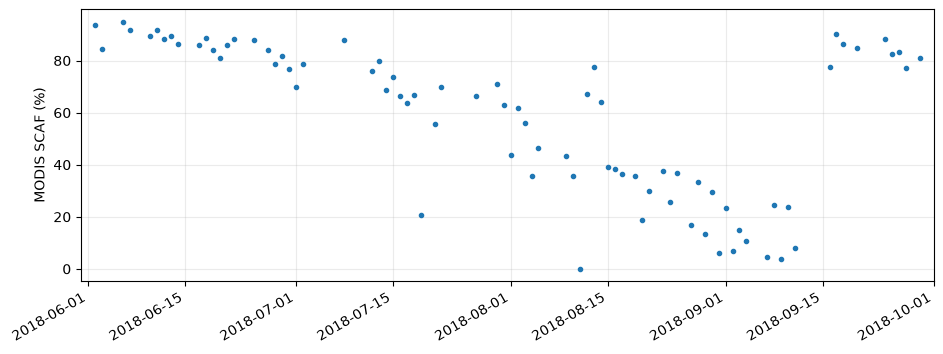

In [18]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(modis_scaf.index, modis_scaf.values, marker=".", linestyle="")
ax.set(ylabel="MODIS SCAF (%)")
ax.grid(alpha=0.25)
ax.set_xlim(
    date.fromisoformat(start_date) - timedelta(days=1),
    date.fromisoformat(end_date) + timedelta(days=1),
)
fig.autofmt_xdate()
plt.show()

In [19]:
modis_sla = modis_scaf.dropna().apply(
    lambda scaf: (
        snowline_altitude(glacier_outline, scaf/100)
    )
).rename("sla")

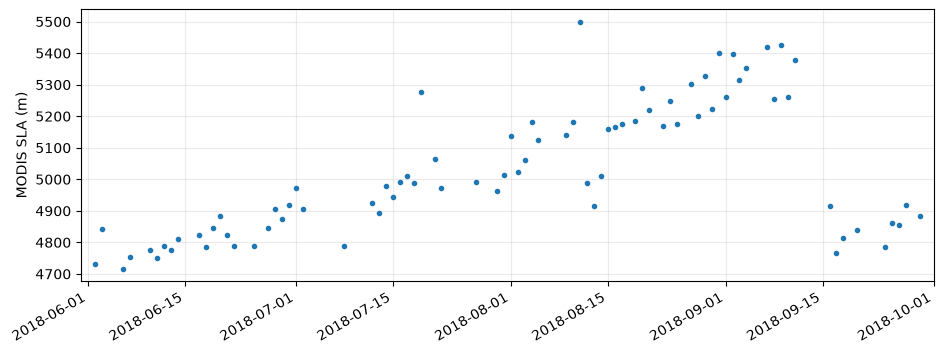

In [20]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(modis_sla.index, modis_sla.values, marker=".", linestyle="")
ax.set(ylabel="MODIS SLA (m)")
ax.grid(alpha=0.25)
ax.set_xlim(
    date.fromisoformat(start_date) - timedelta(days=1),
    date.fromisoformat(end_date) + timedelta(days=1),
)
fig.autofmt_xdate()
plt.show()